# Student Performance Prediction Using Machine Learning

## 1. Understanding the Dataset

### Objective
The objective of this project is to develop a machine learning classification model that predicts a student's academic performance category based on demographic, parental, socioeconomic, and test-preparation-related factors.

### Dataset
The dataset contains information about students along with their mathematics, reading, and writing scores.

For this project, the three subject scores will be used to calculate an overall score. Based on the overall score, students will be categorized into three performance levels:

- Low: Overall score from 0 to 59
- Good: Overall score from 60 to 79
- Excellent: Overall score from 80 to 100

The performance category will be used as the target variable for the classification models.

In [2]:
import pandas as pd

# Load the student performance dataset
df = pd.read_csv("data/StudentsPerformance.csv")

# Display the first five records
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 2. Dataset Structure and Initial Inspection

In this section, we inspect the basic structure of the dataset before performing any preprocessing.

We will check the dataset dimensions, column names, data types, and missing values. This helps us understand what kind of data we are working with and identify any data-quality issues that need to be addressed.

In [3]:
# Check the number of rows and columns
print("Number of rows and columns:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null information
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

Number of rows and columns: (1000, 8)

Column names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB

Missing values in each column:
gender                         0
race/ethnicity 

The dataset contains 1,000 student records and 8 variables. Five variables are categorical and three are numerical. All columns contain 1,000 non-null values, so there are no missing values. Therefore, missing-value imputation is not required

## 3. Checking for Duplicate Records

Duplicate records can affect the learning process because repeated observations may give certain patterns more importance than they should have.

Therefore, we check the dataset for completely duplicated rows before continuing with preprocessing.

In [4]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the patterns, distributions, and characteristics of the dataset before applying machine learning algorithms.

We first examine the statistical summary of the numerical variables to understand their central tendency, spread, and range.

In [5]:
# Display statistical summary of numerical features
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## 5. Distribution of Subject Scores

We visualize the distributions of mathematics, reading, and writing scores to understand how student performance is spread across the three subjects.

Histograms are used because they show the frequency of observations across different score ranges.

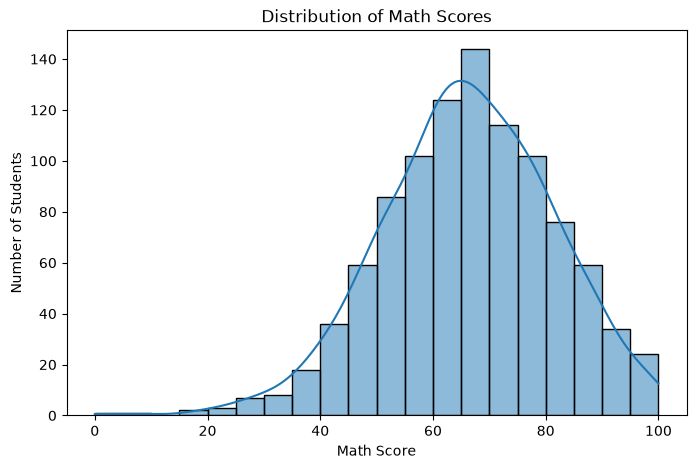

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of each subject score
plt.figure(figsize=(8, 5))

sns.histplot(df["math score"], bins=20, kde=True)

plt.title("Distribution of Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.show()

### Interpretation

The math score distribution shows that most students scored between approximately 50 and 80, with the highest concentration around the 60–70 range. The distribution has a slightly longer tail toward the lower scores. A small number of students obtained very low scores, but these values are valid observations and are not removed automatically as outliers.

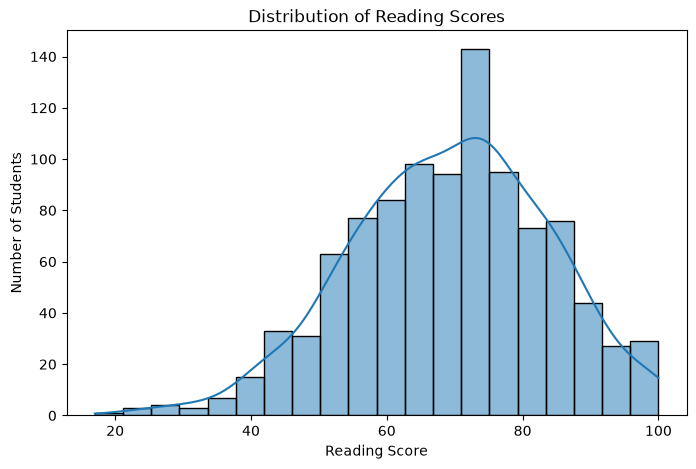

In [7]:
# Plot the distribution of reading scores
plt.figure(figsize=(8, 5))

sns.histplot(df["reading score"], bins=20, kde=True)

plt.title("Distribution of Reading Scores")
plt.xlabel("Reading Score")
plt.ylabel("Number of Students")
plt.show()

### Interpretation of Reading Scores

The reading score distribution shows that most students scored between approximately 50 and 90. The largest concentration of students is around the 70–75 score range. Only a small number of students obtained very low scores, while the number of students also decreases toward the highest scores. Overall, the distribution is broadly unimodal and does not show any obvious extreme observations that need to be removed based on the histogram alone.

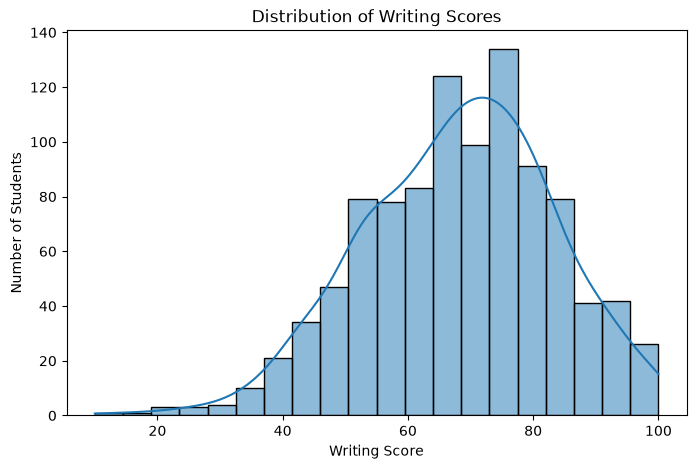

In [8]:
# Plot the distribution of writing scores
plt.figure(figsize=(8, 5))

sns.histplot(df["writing score"], bins=20, kde=True)

plt.title("Distribution of Writing Scores")
plt.xlabel("Writing Score")
plt.ylabel("Number of Students")
plt.show()

### Interpretation of Writing Scores

The writing score distribution shows that most students scored approximately between 50 and 85. The largest concentration is observed in the 65–80 range. Only a small number of students obtained scores below 30, while the frequency gradually decreases toward the higher score range. Overall, the distribution is broadly unimodal, and no observations are removed based only on the histogram.

## 6. Overall Score Distribution

Overall Score = (Math + Reading + Writing) / 3
The three subject scores are combined to calculate an overall academic score for each student.

The overall score provides a single measure of academic performance and will be used to investigate suitable performance categories for the classification task.

The distribution of the overall score will be examined before defining the target classes.

In [9]:
# Calculate the overall score for each student
df["overall_score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
) / 3

# Display basic statistics of the overall score
df["overall_score"].describe()

count    1000.000000
mean       67.770667
std        14.257326
min         9.000000
25%        58.333333
50%        68.333333
75%        77.666667
max       100.000000
Name: overall_score, dtype: float64

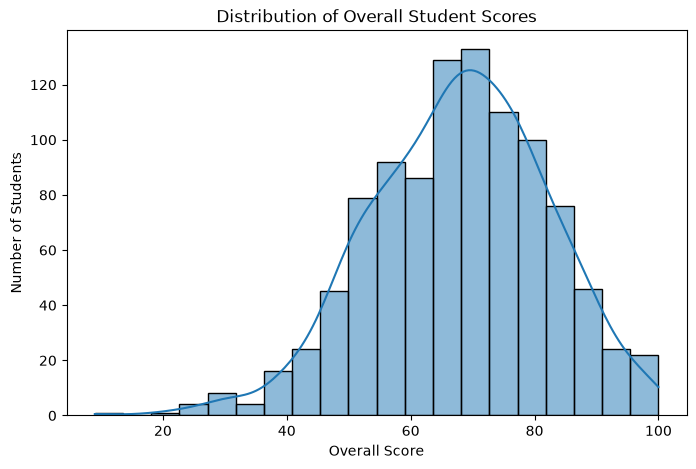

In [10]:
# Plot the distribution of overall scores
plt.figure(figsize=(8, 5))

sns.histplot(df["overall_score"], bins=20, kde=True)

plt.title("Distribution of Overall Student Scores")
plt.xlabel("Overall Score")
plt.ylabel("Number of Students")
plt.show()

### Interpretation of Overall Score Distribution

The overall score distribution shows that most students have scores between approximately 50 and 85, with the highest concentration around the 65–75 range. Only a small number of students have very low overall scores. The frequency gradually decreases toward the higher score range after approximately 80–85. Overall, the distribution is broadly unimodal with a longer lower-score tail.

The distribution is examined before defining the performance categories so that the target classes are based on the characteristics of the dataset.

In [11]:
# Define the proposed performance ranges
low = (df["overall_score"] < 60).sum()
good = ((df["overall_score"] >= 60) & (df["overall_score"] < 80)).sum()
excellent = (df["overall_score"] >= 80).sum()

# Calculate percentages
total = len(df)

print("Potential Performance Distribution")
print("-" * 40)
print(f"Low       : {low} students ({low / total * 100:.1f}%)")
print(f"Good      : {good} students ({good / total * 100:.1f}%)")
print(f"Excellent : {excellent} students ({excellent / total * 100:.1f}%)")

Potential Performance Distribution
----------------------------------------
Low       : 285 students (28.5%)
Good      : 517 students (51.7%)
Excellent : 198 students (19.8%)


## Step 7: Define the Prediction Problem

The objective of this project is to predict a student's writing performance category using the available student information and other academic scores.

This is a supervised multi-class classification problem because the target consists of three categories:

- Low
- Good
- Excellent

The writing score is used to create the target categories but is not used as an input feature. This prevents target leakage.

The input features considered are:
- Gender
- Race/ethnicity
- Parental level of education
- Lunch
- Test preparation course
- Math score
- Reading score

## Step 8: Create the Target Variable

The writing score is converted into three performance categories for classification.

The categories are defined as follows:

- Scores below 60 are classified as Low.
- Scores from 60 to below 80 are classified as Good.
- Scores of 80 or above are classified as Excellent.

The original writing score will not be used as an input feature because it is the variable being predicted.

In [64]:
# Create writing performance categories

def assign_writing_performance(score):
    if score < 60:
        return "Low"
    elif score < 80:
        return "Good"
    else:
        return "Excellent"


df["writing_performance"] = df["writing score"].apply(
    assign_writing_performance
)

# Display the target distribution
print("Writing Performance Distribution")
print("---------------------------------")
print(df["writing_performance"].value_counts())

print("\nPercentage Distribution")
print("-----------------------")
print(
    df["writing_performance"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Writing Performance Distribution
---------------------------------
writing_performance
Good         484
Low          281
Excellent    235
Name: count, dtype: int64

Percentage Distribution
-----------------------
writing_performance
Good         48.4
Low          28.1
Excellent    23.5
Name: proportion, dtype: float64


### Interpretation

The target variable contains three performance categories. Good is the largest category with 48.4% of students, followed by Low with 28.1% and Excellent with 23.5%.

The class distribution is reasonably balanced, although Good contains a slightly larger proportion of observations. Therefore, all three categories can be considered during model training and evaluation.

## 8. Analysis of Categorical Features

The dataset contains several categorical variables describing student characteristics and educational background.

We examine the distribution of these variables before preprocessing. This helps us understand the available categories and identify whether any category has very few observations.

In [14]:
# Display the unique categories in each categorical feature
categorical_features = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

for column in categorical_features:
    print(f"\n{column}")
    print(df[column].value_counts())


gender
gender
female    518
male      482
Name: count, dtype: int64

race/ethnicity
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parental level of education
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

lunch
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

test preparation course
test preparation course
none         642
completed    358
Name: count, dtype: int64


## Step 9: Feature Selection

The input features are selected based on the information available for predicting writing performance.

The model uses demographic, socioeconomic, test preparation, mathematics score, and reading score information.

The writing score is excluded from the input features because it is used to create the target variable. Including it would cause target leakage and would make the model evaluation unreliable.

In [65]:
# Define input features
feature_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
    "math score",
    "reading score"
]

X = df[feature_columns]

# Define target
y = df["writing_performance"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nShape of input features:", X.shape)
print("Shape of target:", y.shape)

Input features:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score']

Target:
writing_performance

Shape of input features: (1000, 7)
Shape of target: (1000,)


## Step 10: Categorical Features vs Writing Performance

The relationship between categorical student characteristics and writing performance is examined.

This analysis helps identify whether writing performance differs across groups based on gender, race/ethnicity, parental education, lunch type, and test preparation course.

In [66]:
categorical_features = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

for feature in categorical_features:
    print("\n" + "=" * 60)
    print(feature.upper())
    print("=" * 60)

    counts = pd.crosstab(
        df[feature],
        df["writing_performance"]
    )

    percentages = pd.crosstab(
        df[feature],
        df["writing_performance"],
        normalize="index"
    ).mul(100).round(1)

    print("\nCounts:")
    print(counts)

    print("\nPercentage distribution:")
    print(percentages)


GENDER

Counts:
writing_performance  Excellent  Good  Low
gender                                   
female                     172   252   94
male                        63   232  187

Percentage distribution:
writing_performance  Excellent  Good   Low
gender                                    
female                    33.2  48.6  18.1
male                      13.1  48.1  38.8

RACE/ETHNICITY

Counts:
writing_performance  Excellent  Good  Low
race/ethnicity                           
group A                     15    37   37
group B                     38    91   61
group C                     75   150   94
group D                     67   136   59
group E                     40    70   30

Percentage distribution:
writing_performance  Excellent  Good   Low
race/ethnicity                            
group A                   16.9  41.6  41.6
group B                   20.0  47.9  32.1
group C                   23.5  47.0  29.5
group D                   25.6  51.9  22.5
group E       

## Step 11: Categorical Features and Writing Performance Visualization

Percentage-based bar charts are used to visualize the relationship between categorical student characteristics and writing performance.

Using percentages rather than raw counts allows groups with different numbers of students to be compared fairly.

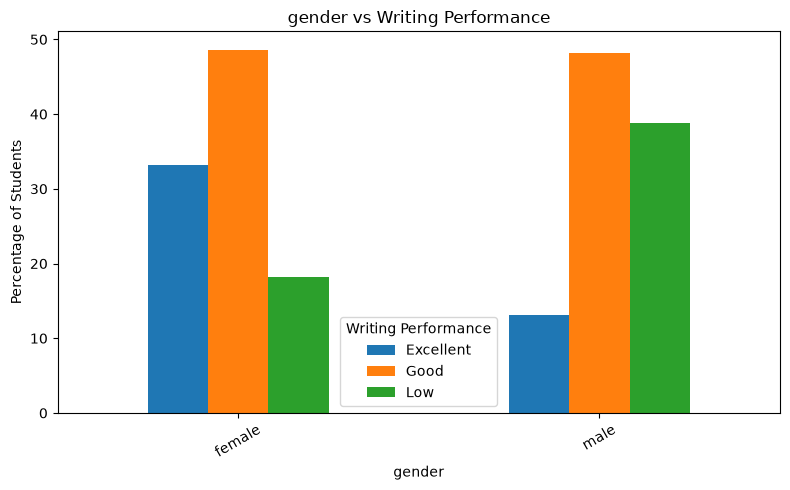

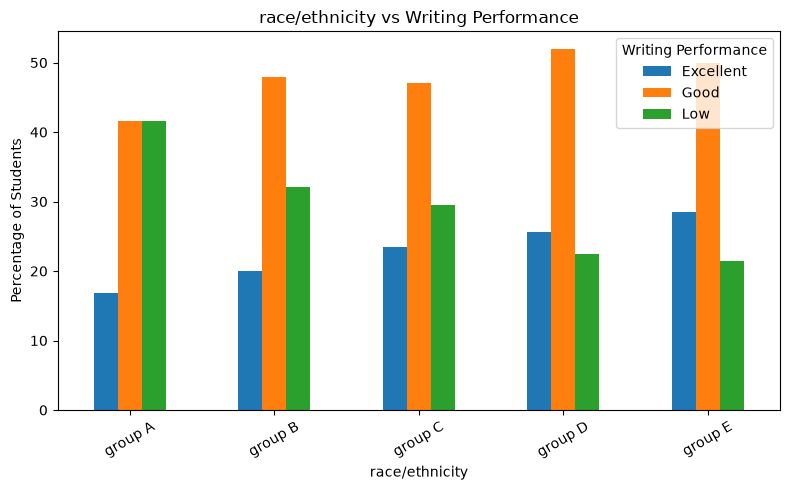

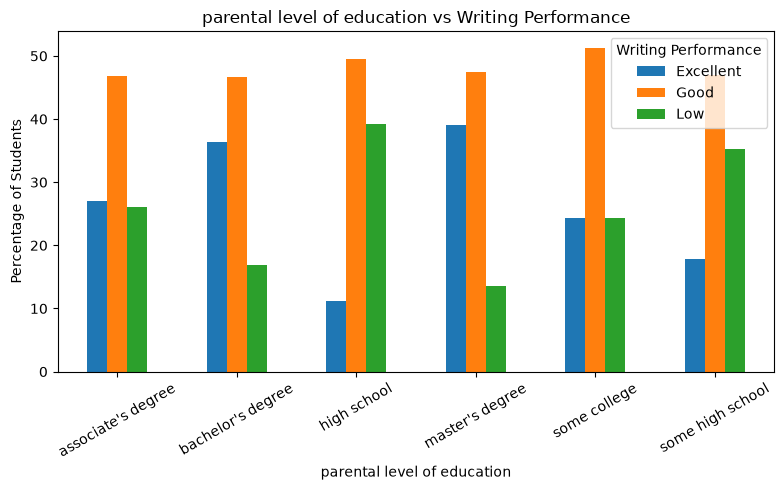

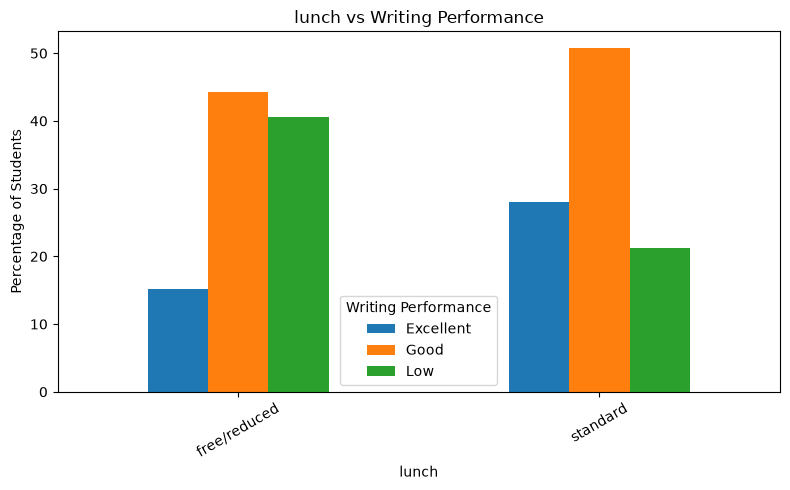

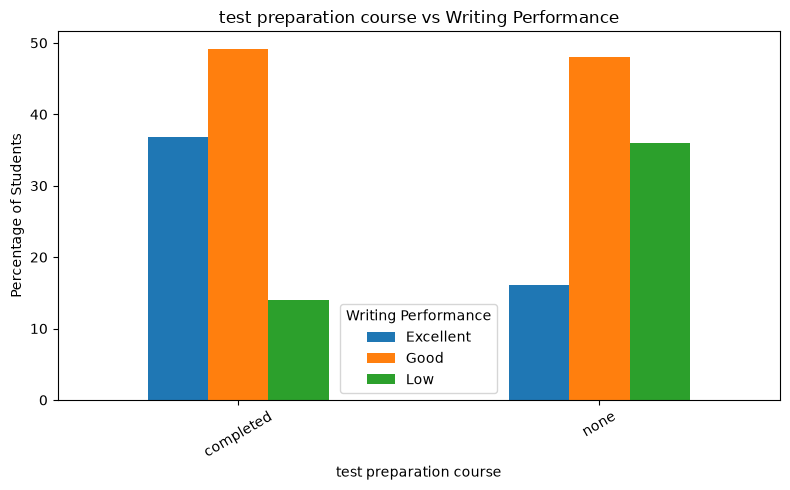

In [67]:
for feature in categorical_features:

    percentage_table = pd.crosstab(
        df[feature],
        df["writing_performance"],
        normalize="index"
    ).mul(100)

    percentage_table.plot(
        kind="bar",
        figsize=(8, 5)
    )

    plt.title(f"{feature} vs Writing Performance")
    plt.xlabel(feature)
    plt.ylabel("Percentage of Students")
    plt.xticks(rotation=30)
    plt.legend(title="Writing Performance")
    plt.tight_layout()
    plt.show()

## Step 12: Numerical Features vs Writing Performance

The relationship between math score, reading score, and writing performance is analyzed.

Boxplots are used to compare the score distributions across the three writing performance categories.

This helps determine whether students with higher math or reading scores tend to have higher writing performance.

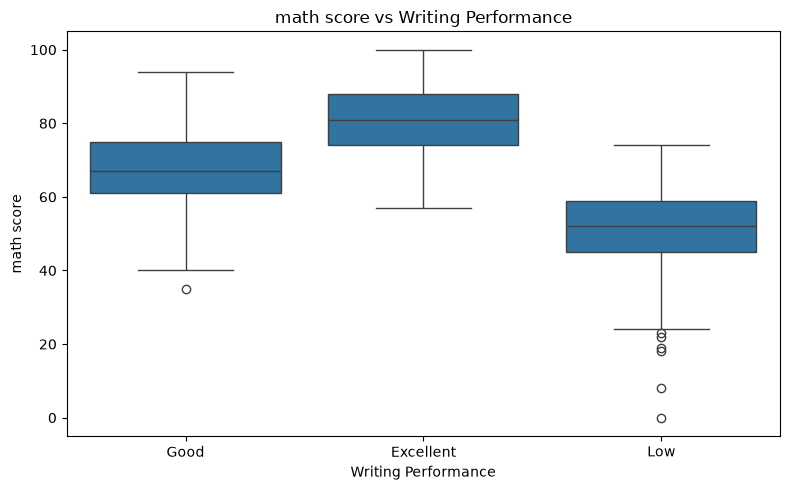

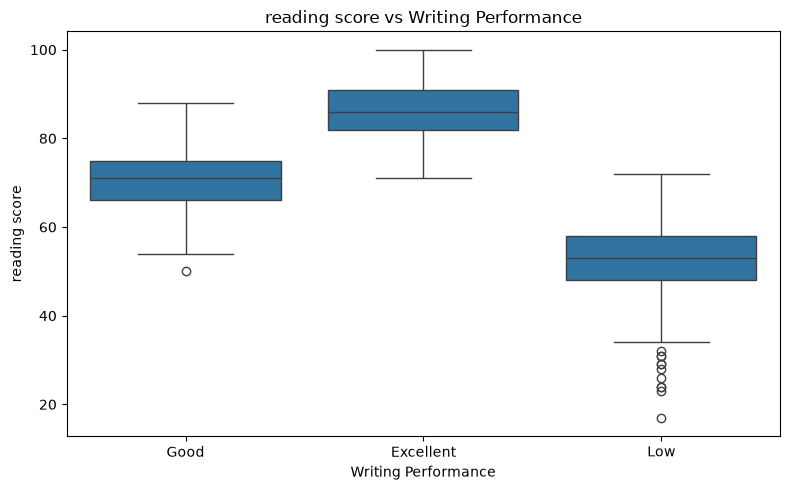

In [68]:
numerical_features = [
    "math score",
    "reading score"
]

for feature in numerical_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="writing_performance",
        y=feature
    )

    plt.title(f"{feature} vs Writing Performance")
    plt.xlabel("Writing Performance")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

## Step 13: Correlation Analysis

Correlation analysis is performed to examine the linear relationship between the numerical score variables.

The analysis helps us understand how strongly mathematics and reading scores are related to writing score.

A positive correlation indicates that higher values of one score tend to be associated with higher values of another score.

In [69]:
# Select the numerical score columns
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

# Calculate the correlation matrix
correlation_matrix = df[score_columns].corr()

print("Correlation Matrix:")
print(correlation_matrix.round(3))

Correlation Matrix:
               math score  reading score  writing score
math score          1.000          0.818          0.803
reading score       0.818          1.000          0.955
writing score       0.803          0.955          1.000


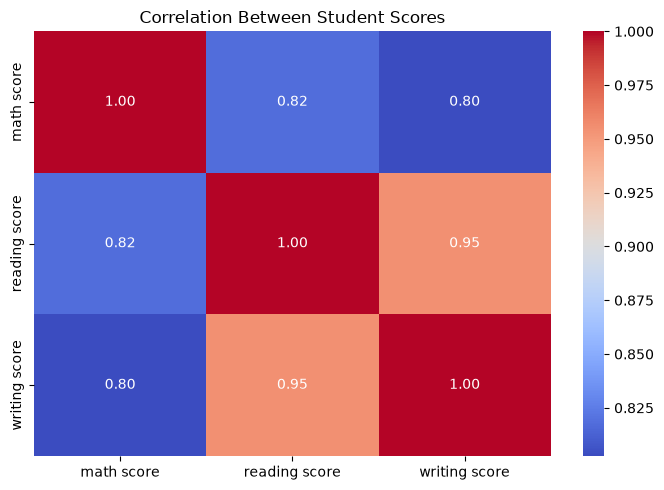

In [70]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Student Scores")
plt.tight_layout()
plt.show()

## Step 14: Outlier Analysis

Potential outliers in the numerical input features are identified using the Interquartile Range (IQR) method.

Outliers are not automatically removed because an unusually high or low score may still represent a valid student's performance.

In [71]:
# Detect potential outliers using the IQR method

for feature in numerical_features:
    
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]
    
    print(f"\n{feature}")
    print("-" * 40)
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")


math score
----------------------------------------
Q1: 57.00
Q3: 77.00
IQR: 20.00
Lower bound: 27.00
Upper bound: 107.00
Potential outliers: 8

reading score
----------------------------------------
Q1: 59.00
Q3: 79.00
IQR: 20.00
Lower bound: 29.00
Upper bound: 109.00
Potential outliers: 6


### Interpretation of Outlier Analysis

The IQR method identified 8 potential outliers in math scores and 6 potential outliers in reading scores.

The potential outliers are mainly unusually low scores. They were not removed because they may represent valid student observations rather than data-entry errors.

Therefore, all observations are retained for the machine learning analysis.

## Step 15: Train-Test Split

The dataset is divided into training and testing sets.

80% of the observations are used to train the machine learning models, while 20% are reserved for final evaluation.

Stratified splitting is used so that the proportions of Low, Good, and Excellent writing performance remain similar in both datasets.

In [72]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(1)
)

print("\nTesting target distribution:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(1)
)

Training samples: 800
Testing samples: 200

Training target distribution:
writing_performance
Good         48.4
Low          28.1
Excellent    23.5
Name: proportion, dtype: float64

Testing target distribution:
writing_performance
Good         48.5
Low          28.0
Excellent    23.5
Name: proportion, dtype: float64


## Step 16: Data Preprocessing

The input features contain both categorical and numerical variables.

Categorical variables are converted into numerical representations using one-hot encoding so that they can be used by machine learning algorithms.

The preprocessing steps will be placed inside a pipeline. This ensures that preprocessing is learned only from the training data and helps prevent data leakage.

In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define feature types
categorical_features = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

numerical_features = [
    "math score",
    "reading score"
]

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## Step 17: Logistic Regression

Logistic Regression is used as the first classification model.

Although its name contains the word "regression", it is commonly used for classification problems. It estimates the probability of each class and assigns the class with the highest probability.

A pipeline is used to combine the preprocessing step with the Logistic Regression model. This ensures that the same preprocessing is applied consistently during training and prediction.

In [74]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


c:\Users\Siri\OneDrive\Desktop\Student_Performance_ML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Step 18: Evaluate Logistic Regression

The Logistic Regression model is evaluated using the unseen test data.

Accuracy is used to measure overall prediction correctness. Precision, recall, and F1-score are also examined for each writing performance category to understand how well the model performs across Low, Good, and Excellent students.

In [75]:
# Make predictions on the test set
y_pred_logistic = logistic_model.predict(X_test)

# Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_logistic,
        zero_division=0
    )
)

Logistic Regression Accuracy: 0.8900

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.82      0.87      0.85        47
        Good       0.89      0.88      0.89        97
         Low       0.95      0.93      0.94        56

    accuracy                           0.89       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.89      0.89      0.89       200



## Step 19: Confusion Matrix

A confusion matrix is used to examine the detailed classification performance of the Logistic Regression model.

It shows the number of correctly and incorrectly classified students for each writing performance category.

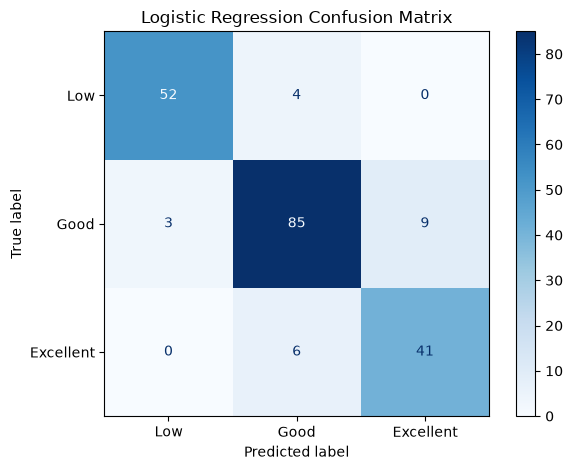

In [78]:
# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=["Low", "Good", "Excellent"]
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Good", "Excellent"]
)

disp.plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 20: Decision Tree Classifier

A Decision Tree Classifier is trained as the second machine learning model.

A decision tree makes predictions by creating a series of decision rules based on the input features. It can capture non-linear relationships between the features and the target.

In [79]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create Decision Tree pipeline
decision_tree_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", DecisionTreeClassifier(random_state=42))
    ]
)

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


## Step 21: Evaluate Decision Tree

The Decision Tree model is evaluated using the same test dataset used for Logistic Regression.

Accuracy, precision, recall, and F1-score are examined to determine how well the model predicts each writing performance category.

In [80]:
# Make predictions
y_pred_tree = decision_tree_model.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print(f"Decision Tree Accuracy: {tree_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_tree,
        zero_division=0
    )
)

Decision Tree Accuracy: 0.8300

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.75      0.83      0.79        47
        Good       0.84      0.80      0.82        97
         Low       0.89      0.88      0.88        56

    accuracy                           0.83       200
   macro avg       0.83      0.84      0.83       200
weighted avg       0.83      0.83      0.83       200



### Interpretation of Decision Tree Results

The Decision Tree achieved an accuracy of 83.0% on the test set.

The model performed reasonably well across all three writing performance categories, with a macro F1-score of 0.83. However, its overall performance was lower than Logistic Regression, which achieved 89.0% accuracy and a macro F1-score of 0.89.

Therefore, Logistic Regression currently remains the better-performing model.

## Step 22: Random Forest Classifier

A Random Forest Classifier is trained as the third machine learning model.

Random Forest combines multiple decision trees and aggregates their predictions. This can improve generalization and reduce the risk of relying too heavily on a single decision tree.

In [81]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## Step 23: Evaluate Random Forest

The Random Forest model is evaluated using the same unseen test dataset.

Accuracy, precision, recall, and F1-score are calculated to compare its performance with the previously evaluated models.

In [82]:
# Make predictions
y_pred_rf = random_forest_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        zero_division=0
    )
)

Random Forest Accuracy: 0.8800

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.83      0.83      0.83        47
        Good       0.86      0.90      0.88        97
         Low       0.96      0.89      0.93        56

    accuracy                           0.88       200
   macro avg       0.88      0.87      0.88       200
weighted avg       0.88      0.88      0.88       200



### Interpretation of Random Forest Results

The Random Forest model achieved an accuracy of 88.0% and a macro F1-score of 0.88 on the test set.

The model performed well across all three writing performance categories, with F1-scores of 0.83 for Excellent, 0.88 for Good, and 0.93 for Low.

However, Logistic Regression achieved slightly better overall performance with 89.0% accuracy and a macro F1-score of 0.89. Therefore, Logistic Regression remains the best-performing model at this stage.

## Step 24: K-Nearest Neighbors Classifier

K-Nearest Neighbors is evaluated as another classification approach.

KNN classifies a new student based on the performance categories of nearby observations in the feature space.

In [83]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN pipeline
knn_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]
)

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


## Step 25: Evaluate K-Nearest Neighbors

The K-Nearest Neighbors model is evaluated using the same test dataset.

Accuracy, precision, recall, and F1-score are calculated to compare its performance with the other classification models.

In [84]:
# Make predictions
y_pred_knn = knn_model.predict(X_test)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {knn_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_knn,
        zero_division=0
    )
)

KNN Accuracy: 0.8700

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.85      0.85      0.85        47
        Good       0.88      0.85      0.86        97
         Low       0.87      0.93      0.90        56

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



### Interpretation of KNN Results

The K-Nearest Neighbors model achieved an accuracy of 87.0% and a macro F1-score of 0.87.

The model performed consistently across all three writing performance categories, with F1-scores of 0.85 for Excellent, 0.86 for Good, and 0.90 for Low.

However, Logistic Regression remains the best-performing model so far, achieving 89.0% accuracy and a macro F1-score of 0.89.

## Step 26: Support Vector Machine

A Support Vector Machine classifier is trained as another classification approach.

SVM attempts to find decision boundaries that separate the different writing performance categories in the feature space.

In [85]:
from sklearn.svm import SVC

# Create SVM pipeline
svm_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", SVC())
    ]
)

# Train the model
svm_model.fit(X_train, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


## Step 27: Evaluate Support Vector Machine

The Support Vector Machine model is evaluated using the same test dataset as the previous models.

Accuracy, precision, recall, and F1-score are calculated to compare its performance with the other classification models.

In [86]:
# Make predictions
y_pred_svm = svm_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"SVM Accuracy: {svm_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        zero_division=0
    )
)

SVM Accuracy: 0.8600

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.87      0.87      0.87        47
        Good       0.85      0.87      0.86        97
         Low       0.87      0.84      0.85        56

    accuracy                           0.86       200
   macro avg       0.86      0.86      0.86       200
weighted avg       0.86      0.86      0.86       200



### Interpretation of SVM Results

The Support Vector Machine achieved an accuracy of 86.0% and a macro F1-score of 0.86.

The model showed balanced performance across all three writing performance categories, with F1-scores of 0.87 for Excellent, 0.86 for Good, and 0.85 for Low.

However, Logistic Regression remains the best-performing model, achieving 89.0% accuracy and a macro F1-score of 0.89.

## Step 28: Model Performance Comparison

The performance of all five classification models is compared using test accuracy and macro F1-score.

The model with the strongest overall performance will be considered for further evaluation and tuning.

In [87]:
# Create model comparison table

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        rf_accuracy,
        knn_accuracy,
        svm_accuracy
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_logistic, average="macro"),
        f1_score(y_test, y_pred_tree, average="macro"),
        f1_score(y_test, y_pred_rf, average="macro"),
        f1_score(y_test, y_pred_knn, average="macro"),
        f1_score(y_test, y_pred_svm, average="macro")
    ]
})

# Sort by accuracy
model_comparison = model_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print(model_comparison.round(4))

                 Model  Accuracy  Macro F1
0  Logistic Regression      0.89    0.8892
1        Random Forest      0.88    0.8782
2                  KNN      0.87    0.8703
3                  SVM      0.86    0.8613
4        Decision Tree      0.83    0.8306


### Interpretation of Model Comparison

The five classification models were compared using test accuracy and macro F1-score.

Logistic Regression achieved the highest performance, with an accuracy of 89.0% and a macro F1-score of 0.8892. Random Forest was the second-best model with 88.0% accuracy, followed by KNN with 87.0%, SVM with 86.0%, and Decision Tree with 83.0%.

Since Logistic Regression achieved the highest accuracy and macro F1-score, it is selected as the current best-performing model for further validation and tuning.

## Step 29: Cross-Validation of Logistic Regression

Five-fold stratified cross-validation is used to evaluate the consistency of the Logistic Regression model.

The training data is divided into five folds. The model is trained and validated multiple times using different folds.

The test set remains untouched during cross-validation.

In [88]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Logistic Regression using training data only
cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Logistic Regression Cross-Validation Scores:")
print(cv_scores)

print(f"\nMean CV Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

c:\Users\Siri\OneDrive\Desktop\Student_Performance_ML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\Siri\OneDrive\Desktop\Student_Performance_ML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
   

Logistic Regression Cross-Validation Scores:
[0.86875 0.85    0.8625  0.83125 0.88125]

Mean CV Accuracy: 0.8587
Standard Deviation: 0.0170


c:\Users\Siri\OneDrive\Desktop\Student_Performance_ML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Step 30: Improving Logistic Regression Convergence

The cross-validation results show that Logistic Regression performs consistently, but a convergence warning was generated during training.

To improve numerical optimization, the numerical features are standardized using StandardScaler. The categorical features continue to be one-hot encoded.

The preprocessing remains inside the pipeline to prevent data leakage.

In [89]:
from sklearn.preprocessing import StandardScaler

# Create improved preprocessing
preprocessor_scaled = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Create improved Logistic Regression pipeline
logistic_model_scaled = Pipeline(
    steps=[
        ("preprocessing", preprocessor_scaled),
        ("model", LogisticRegression(max_iter=2000))
    ]
)

print("Scaled Logistic Regression pipeline created successfully.")

Scaled Logistic Regression pipeline created successfully.


## Step 31: Train Scaled Logistic Regression

The improved Logistic Regression pipeline is trained using the training data.

Standardization of the numerical features helps the optimization algorithm converge more reliably.

In [90]:
# Train the scaled Logistic Regression model

logistic_model_scaled.fit(X_train, y_train)

print("Scaled Logistic Regression model trained successfully.")

Scaled Logistic Regression model trained successfully.


In [ ]:
## Step 32: Evaluate Scaled Logistic Regression

The scaled Logistic Regression model is evaluated on the unseen test set.

Its performance is compared with the original Logistic Regression model to determine whether feature scaling improves or maintains predictive performance while resolving the convergence issue.

In [91]:
# Make predictions
y_pred_scaled_lr = logistic_model_scaled.predict(X_test)

# Calculate metrics
scaled_lr_accuracy = accuracy_score(
    y_test,
    y_pred_scaled_lr
)

scaled_lr_macro_f1 = f1_score(
    y_test,
    y_pred_scaled_lr,
    average="macro"
)

scaled_lr_weighted_f1 = f1_score(
    y_test,
    y_pred_scaled_lr,
    average="weighted"
)

print(f"Scaled Logistic Regression Accuracy: {scaled_lr_accuracy:.4f}")
print(f"Scaled Logistic Regression Macro F1: {scaled_lr_macro_f1:.4f}")
print(f"Scaled Logistic Regression Weighted F1: {scaled_lr_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_scaled_lr,
        zero_division=0
    )
)

Scaled Logistic Regression Accuracy: 0.8800
Scaled Logistic Regression Macro F1: 0.8790
Scaled Logistic Regression Weighted F1: 0.8805

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.82      0.85      0.83        47
        Good       0.88      0.88      0.88        97
         Low       0.94      0.91      0.93        56

    accuracy                           0.88       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.88      0.88      0.88       200



## Step 33: Cross-Validation of Scaled Logistic Regression

Five-fold stratified cross-validation is performed on the training data to evaluate the consistency of the scaled Logistic Regression model.

Only the training data is used during cross-validation. The test set remains untouched.

In [92]:
# Perform 5-fold cross-validation

cv_scores_scaled = cross_val_score(
    logistic_model_scaled,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Scaled Logistic Regression Cross-Validation Scores:")
print(cv_scores_scaled)

print(f"\nMean CV Accuracy: {cv_scores_scaled.mean():.4f}")
print(f"Standard Deviation: {cv_scores_scaled.std():.4f}")

Scaled Logistic Regression Cross-Validation Scores:
[0.86875 0.8625  0.88125 0.83125 0.8875 ]

Mean CV Accuracy: 0.8663
Standard Deviation: 0.0196


## Step 34: Hyperparameter Tuning for Logistic Regression

The Logistic Regression model is tuned using GridSearchCV.

The regularization parameter C is tested across several values. Five-fold stratified cross-validation is used to identify the value that provides the best validation accuracy.

The test set remains untouched during hyperparameter tuning.

In [93]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameter values
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# Create GridSearchCV
logistic_grid = GridSearchCV(
    estimator=logistic_model_scaled,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Fit using training data only
logistic_grid.fit(X_train, y_train)

print("Best parameters:")
print(logistic_grid.best_params_)

print(
    f"\nBest cross-validation accuracy: "
    f"{logistic_grid.best_score_:.4f}"
)

Best parameters:
{'model__C': 1}

Best cross-validation accuracy: 0.8663


### Interpretation of Hyperparameter Tuning

GridSearchCV identified C = 1 as the best regularization parameter, with a mean cross-validation accuracy of 86.63%.

Since C = 1 is the default value used by the original Logistic Regression model, hyperparameter tuning did not identify an improved configuration.

Therefore, the original Logistic Regression model remains the strongest model based on the observed test accuracy of 89.0%.

## Step 35: Final Evaluation of Tuned Logistic Regression

The best Logistic Regression configuration identified through cross-validation is evaluated on the untouched test set.

This provides the final test performance of the tuned model.

In [94]:
# Get the best tuned model
best_logistic_model = logistic_grid.best_estimator_

# Predict on the test set
y_pred_tuned = best_logistic_model.predict(X_test)

# Calculate final metrics
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_macro_f1 = f1_score(y_test, y_pred_tuned, average="macro")
tuned_weighted_f1 = f1_score(y_test, y_pred_tuned, average="weighted")

print(f"Tuned Logistic Regression Accuracy: {tuned_accuracy:.4f}")
print(f"Tuned Logistic Regression Macro F1: {tuned_macro_f1:.4f}")
print(f"Tuned Logistic Regression Weighted F1: {tuned_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

Tuned Logistic Regression Accuracy: 0.8800
Tuned Logistic Regression Macro F1: 0.8790
Tuned Logistic Regression Weighted F1: 0.8805

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.82      0.85      0.83        47
        Good       0.88      0.88      0.88        97
         Low       0.94      0.91      0.93        56

    accuracy                           0.88       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.88      0.88      0.88       200



## Step 36: Final Model Selection

Based on the evaluation results, Logistic Regression achieved the best overall performance among the five classification models.

The original Logistic Regression model achieved:

- Test Accuracy: 89.0%
- Macro F1-score: 0.8892

Random Forest achieved 88.0% accuracy, while KNN, SVM, and Decision Tree achieved 87.0%, 86.0%, and 83.0%, respectively.

The scaled and tuned Logistic Regression model achieved 88.0% accuracy and therefore did not improve upon the original model.

Based on the test accuracy and macro F1-score, the original Logistic Regression model is selected as the final model.

## Step 37: Final Confusion Matrix

The confusion matrix of the selected Logistic Regression model is examined to understand the types of correct and incorrect predictions made for each writing performance category.

The matrix shows how many students were correctly classified as Low, Good, or Excellent and where misclassifications occurred.

Confusion Matrix:
[[52  4  0]
 [ 3 85  9]
 [ 0  6 41]]


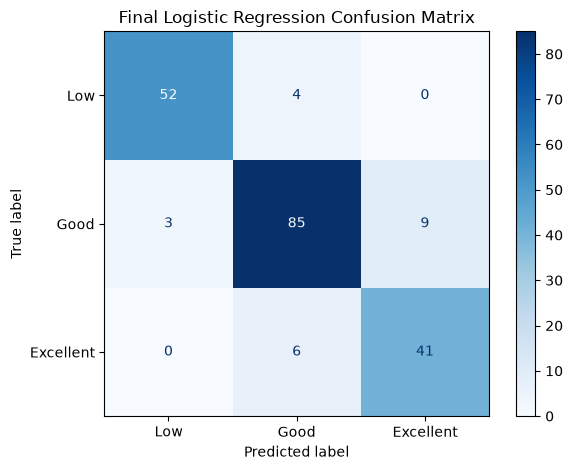

In [95]:
# Create the final confusion matrix

final_cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=["Low", "Good", "Excellent"]
)

print("Confusion Matrix:")
print(final_cm)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Low", "Good", "Excellent"]
)

disp.plot(cmap="Blues")

plt.title("Final Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 38: Feature Influence Analysis

The coefficients of the Logistic Regression model are examined to understand which input features have the strongest influence on the predicted writing performance categories.

Because categorical variables were one-hot encoded, the transformed feature names are extracted before examining the model coefficients.

This analysis provides interpretability and helps explain how the model makes its predictions.

In [96]:
# Get transformed feature names
feature_names = (
    logistic_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

# Get Logistic Regression model
lr_model = logistic_model.named_steps["model"]

# Create coefficient DataFrame
coefficients = pd.DataFrame(
    lr_model.coef_,
    columns=feature_names,
    index=lr_model.classes_
)

print("Model classes:")
print(lr_model.classes_)

print("\nCoefficient shape:")
print(coefficients.shape)

Model classes:
['Excellent' 'Good' 'Low']

Coefficient shape:
(3, 19)


## Step 39: Analyze Feature Coefficients

The absolute values of the Logistic Regression coefficients are used to identify the features with the strongest influence on the model's predictions.

Larger absolute coefficient values indicate a stronger influence on the classification decision.

In [97]:
# Find the strongest features for each performance class

for class_name in coefficients.index:
    
    print("\n" + "=" * 50)
    print(f"Top Features for {class_name}")
    print("=" * 50)
    
    class_coefficients = coefficients.loc[class_name]
    
    top_features = (
        class_coefficients
        .abs()
        .sort_values(ascending=False)
        .head(10)
    )
    
    print(
        pd.DataFrame({
            "Coefficient": class_coefficients[top_features.index],
            "Absolute Influence": top_features.values
        })
    )


Top Features for Excellent
                                                    Coefficient  \
categorical__gender_female                             1.298795   
categorical__gender_male                              -1.208098   
categorical__parental level of education_bachel...     1.016343   
categorical__test preparation course_completed         0.896278   
categorical__test preparation course_none             -0.805580   
categorical__race/ethnicity_group D                    0.615977   
categorical__parental level of education_some h...    -0.559358   
categorical__race/ethnicity_group E                   -0.520441   
categorical__parental level of education_high s...    -0.493076   
numerical__reading score                               0.353017   

                                                    Absolute Influence  
categorical__gender_female                                    1.298795  
categorical__gender_male                                      1.208098  
categorical__pa

## Step 40: Overall Feature Influence

The average absolute coefficient across the three performance classes is calculated to identify the features that have the strongest overall influence on the Logistic Regression model.

This provides a general measure of feature importance across all three classes.

In [99]:
# Calculate average absolute coefficient across all classes

overall_feature_influence = (
    coefficients.abs()
    .mean(axis=0)
    .sort_values(ascending=False)
)

print("Top 10 Most Influential Features:")
print("----------------------------------")

print(
    overall_feature_influence
    .head(10)
    .round(4)
)

Top 10 Most Influential Features:
----------------------------------
categorical__gender_female                                    0.9734
categorical__gender_male                                      0.8646
categorical__parental level of education_bachelor's degree    0.6776
categorical__test preparation course_completed                0.6587
categorical__test preparation course_none                     0.5499
categorical__race/ethnicity_group D                           0.4107
categorical__parental level of education_some high school     0.3760
categorical__race/ethnicity_group E                           0.3731
categorical__parental level of education_high school          0.3287
categorical__parental level of education_master's degree      0.2908
dtype: float64


## Step 41: Final Model Performance Summary

In [100]:
# Final model performance summary

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "KNN",
        "SVM",
        "Decision Tree"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        knn_accuracy,
        svm_accuracy,
        tree_accuracy
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_logistic, average="macro"),
        f1_score(y_test, y_pred_rf, average="macro"),
        f1_score(y_test, y_pred_knn, average="macro"),
        f1_score(y_test, y_pred_svm, average="macro"),
        f1_score(y_test, y_pred_tree, average="macro")
    ]
})

final_results = final_results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

print(final_results.round(4))

                 Model  Accuracy  Macro F1
0  Logistic Regression      0.89    0.8892
1        Random Forest      0.88    0.8782
2                  KNN      0.87    0.8703
3                  SVM      0.86    0.8613
4        Decision Tree      0.83    0.8306


## Step 42: Predict Writing Performance for a New Student

The selected Logistic Regression model is used to predict the writing performance category of a new student.

The new student's writing score is not provided because writing performance is the outcome being predicted.

In [101]:
# Create data for a new student

new_student = pd.DataFrame({
    "gender": ["female"],
    "race/ethnicity": ["group C"],
    "parental level of education": ["some college"],
    "lunch": ["standard"],
    "test preparation course": ["completed"],
    "math score": [75],
    "reading score": [80]
})

# Predict writing performance
prediction = logistic_model.predict(new_student)

print("Predicted Writing Performance:", prediction[0])

Predicted Writing Performance: Excellent


## Step 43: Prediction Probabilities

The prediction probabilities are calculated to understand the model's confidence in each writing performance category.

The probabilities for Low, Good, and Excellent are compared, and the category with the highest probability is selected as the model's prediction.

In [102]:
# Get prediction probabilities
prediction_probabilities = logistic_model.predict_proba(new_student)

# Get class names
class_names = logistic_model.named_steps["model"].classes_

# Display probabilities
probability_table = pd.DataFrame(
    prediction_probabilities,
    columns=class_names
)

print("Prediction Probabilities:")
print(probability_table.round(4))

print("\nPredicted Writing Performance:")
print(logistic_model.predict(new_student)[0])

Prediction Probabilities:
   Excellent    Good  Low
0     0.8253  0.1747  0.0

Predicted Writing Performance:
Excellent


### Interpretation of New Student Prediction

The final Logistic Regression model predicts that the new student belongs to the Excellent writing performance category.

The model assigns an 82.53% probability to Excellent and a 17.47% probability to Good, while the probability of Low is 0%.

Therefore, the predicted writing performance for this student is Excellent.

## Step 44: Final Conclusion

This project developed a machine learning classification system to predict student writing performance as Low, Good, or Excellent.

Exploratory data analysis was first performed to understand the dataset, examine distributions, identify relationships, and detect potential outliers.

Five classification algorithms were evaluated:
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors
- Support Vector Machine

Logistic Regression achieved the best test performance with an accuracy of 89.0% and a macro F1-score of 0.8892.

Cross-validation was also performed to evaluate model consistency. Hyperparameter tuning did not improve the Logistic Regression model beyond the original configuration.

The final Logistic Regression model was therefore selected for prediction. When tested on a new student with specified demographic information, math score, and reading score, the model predicted Excellent writing performance with an 82.53% probability.

Overall, the results demonstrate that machine learning can effectively classify student writing performance using available student characteristics and academic scores.